In [30]:
# ╔══════════════════════════════════════════════════════════╗
# ║      CELL 1 — Imports & Config                           ║
# ╚══════════════════════════════════════════════════════════╝
import os
import numpy as np
import pandas as pd
import joblib
import pyarrow.parquet as pq
import tensorflow as tf
from tensorflow.keras.models import load_model
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, accuracy_score
)
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns


# ── Paths ─────────────────────────────────────────────────
MODEL    = 'best_model_v2.keras'
SCALER   = 'scaler.pkl'
ENCODER  =  'label_encoder.pkl'
FEATURES = 'feature_names.csv'
EXT_LAB  = '/mnt/d/DATASETS/IDS/External_Test/df_external_combined.parquet'
OUT_PATH = 'External_Test/'
os.makedirs(OUT_PATH, exist_ok=True)

print(f"TF  : {tf.__version__}")
print(f"GPU : {tf.config.list_physical_devices('GPU')}")
print("✅ Ready")

TF  : 2.19.0
GPU : []
✅ Ready


In [31]:
# ╔══════════════════════════════════════════════════════════╗
# ║      CELL 2 — Load Model + Scaler + Encoder              ║
# ╚══════════════════════════════════════════════════════════╝

scaler    = joblib.load(SCALER)
encoder   = joblib.load(ENCODER)
feat_cols = pd.read_csv(FEATURES, header=None, skiprows=1)[0].tolist()
model     = load_model(MODEL)

print(f"Scaler   : {type(scaler).__name__}")
print(f"Features : {len(feat_cols)}")
print(f"Classes  : {encoder.classes_}")
print(f"Model    : {model.name}")
model.summary()
print("\n✅ Model & Artifacts Loaded")

/home/medo/miniconda3/envs/ids_dep/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RobustScaler from version 1.6.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/medo/miniconda3/envs/ids_dep/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.6.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Scaler   : RobustScaler
Features : 65
Classes  : ['Benign' 'Bot' 'DDoS attack-HOIC' 'DDoS attacks-LOIC-HTTP' 'DoS attacks'
 'FTP-BruteForce' 'Reconnaissance' 'SQL Injection' 'SSH-Bruteforce']
Model    : CNN_BiLSTM_Attention_V2


Model: "CNN_BiLSTM_Attention_V2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 65, 1)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv1D)      │ (None, 65, 128)   │        512 │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn1                 │ (None, 65, 128)   │        512 │ conv1[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu1 (Activation)  │ (None, 65, 128)   │          0 │ bn1[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ drop1 (Dropout)     │ (None, 65, 128)   │          0 │ relu1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2 (Conv1D)      │ (None, 65, 256)   │     98,560 │ drop1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn2                 │ (None, 65, 256)   │      1,024 │ conv2[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu2 (Activation)  │ (None, 65, 256)   │          0 │ bn2[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ drop2 (Dropout)     │ (None, 65, 256)   │          0 │ relu2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 32, 256)   │          0 │ drop2[0][0]       │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm1             │ (None, 32, 512)   │  1,050,624 │ pool1[0][0]       │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ drop3 (Dropout)     │ (None, 32, 512)   │          0 │ bilstm1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm2             │ (None, 32, 256)   │    656,384 │ drop3[0][0]       │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ drop4 (Dropout)     │ (None, 32, 256)   │          0 │ bilstm2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32, 1)     │        257 │ drop4[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32)        │          0 │ flatten_1[0][0]   │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector_1     │ (None, 256, 32)   │          0 │ activation_1[0][… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute_1 (Permute) │ (None, 32, 256)   │          0 │ repeat_vector_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 32, 256)   │          0 │ drop4[0][0],      │
│ (Multiply)          │                   │            │ permute_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gap                 │ (None, 256)       │          0 │ multiply_1[0][0]

 Total params: 6,223,904 (23.74 MB)

 Trainable params: 2,073,866 (7.91 MB)

 Non-trainable params: 2,304 (9.00 KB)

 Optimizer params: 4,147,734 (15.82 MB)


✅ Model & Artifacts Loaded


In [32]:
# ╔══════════════════════════════════════════════════════════╗
# ║      CELL 3 — Load & Explore External Data               ║
# ╚══════════════════════════════════════════════════════════╝

df = pq.read_table(EXT_LAB).to_pandas()
print(f"Shape: {df.shape}")
print(f"\n=== Label Distribution ===")
for label, count in df['Label'].value_counts().items():
    pct = count / len(df) * 100
    print(f"  {label:<30} : {count:>6,} ({pct:.1f}%)")

# ── Check missing features ────────────────────────────────
missing = [f for f in feat_cols if f not in df.columns]
extra   = [f for f in df.columns if f not in feat_cols + ['Label']]
print(f"\nMissing features : {missing if missing else 'None ✅'}")
print(f"Extra columns    : {len(extra)}")

# ── Check classes vs training classes ────────────────────
ext_classes   = set(df['Label'].unique())
train_classes = set(encoder.classes_)
unseen = ext_classes - train_classes
print(f"\nClasses in external  : {sorted(ext_classes)}")
print(f"Classes in training  : {sorted(train_classes)}")
print(f"Unseen classes       : {unseen if unseen else 'None ✅'}")
print("\n✅ Data Explored")

Shape: (38792, 81)

=== Label Distribution ===
  DDoS attack-HOIC               : 10,000 (25.8%)
  Bot                            : 10,000 (25.8%)
  DDoS attacks-LOIC-HTTP         : 10,000 (25.8%)
  SQL Injection                  :  3,333 (8.6%)
  SSH-Bruteforce                 :  2,893 (7.5%)
  Reconnaissance                 :  1,000 (2.6%)
  DoS attacks                    :    836 (2.2%)
  Benign                         :    730 (1.9%)

Missing features : None ✅
Extra columns    : 15

Classes in external  : ['Benign', 'Bot', 'DDoS attack-HOIC', 'DDoS attacks-LOIC-HTTP', 'DoS attacks', 'Reconnaissance', 'SQL Injection', 'SSH-Bruteforce']
Classes in training  : ['Benign', 'Bot', 'DDoS attack-HOIC', 'DDoS attacks-LOIC-HTTP', 'DoS attacks', 'FTP-BruteForce', 'Reconnaissance', 'SQL Injection', 'SSH-Bruteforce']
Unseen classes       : None ✅

✅ Data Explored


In [33]:
# ╔══════════════════════════════════════════════════════════╗
# ║      CELL 4 — Preprocess External Data                   ║
# ╚══════════════════════════════════════════════════════════╝

# ── Keep only classes the model knows ────────────────────
df = df[df['Label'].isin(list(encoder.classes_))].copy()
df.reset_index(drop=True, inplace=True)

# ── Clean NaN & Inf ───────────────────────────────────────
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(subset=feat_cols, inplace=True)
df.reset_index(drop=True, inplace=True)

print(f"After cleaning: {len(df):,} rows")
print(f"\n=== Final Label Distribution ===")
for label, count in df['Label'].value_counts().items():
    pct = count / len(df) * 100
    print(f"  {label:<30} : {count:>6,} ({pct:.1f}%)")

# ── Scale & Reshape ───────────────────────────────────────
X      = df[feat_cols].values.astype('float32')
y_true = encoder.transform(df['Label'])

X_scaled = scaler.transform(X).astype('float32')
X_scaled = np.clip(X_scaled, -10, 10)
X_3d     = X_scaled.reshape(-1, len(feat_cols), 1)

print(f"\nX shape : {X_3d.shape}")
print(f"y shape : {y_true.shape}")
print("\n✅ Preprocessing Done")

After cleaning: 38,792 rows

=== Final Label Distribution ===
  DDoS attack-HOIC               : 10,000 (25.8%)
  Bot                            : 10,000 (25.8%)
  DDoS attacks-LOIC-HTTP         : 10,000 (25.8%)
  SQL Injection                  :  3,333 (8.6%)
  SSH-Bruteforce                 :  2,893 (7.5%)
  Reconnaissance                 :  1,000 (2.6%)
  DoS attacks                    :    836 (2.2%)
  Benign                         :    730 (1.9%)

X shape : (38792, 65, 1)
y shape : (38792,)

✅ Preprocessing Done


In [34]:
# ╔══════════════════════════════════════════════════════════╗
# ║      CELL 5 — Predict                                    ║
# ╚══════════════════════════════════════════════════════════╝

print("Predicting...")
y_pred_prob = model.predict(X_3d, batch_size=2048, verbose=1)
y_pred      = np.argmax(y_pred_prob, axis=1)
y_conf      = np.max(y_pred_prob, axis=1)

present_classes = sorted(set(y_true))
present_names   = [encoder.classes_[i] for i in present_classes]

print("\n" + "="*65)
print("  CyberHawk-2026 — External Lab Test Results")
print("="*65)
report = classification_report(
    y_true, y_pred,
    labels=present_classes,
    target_names=present_names,
    digits=4
)
print(report)

acc = accuracy_score(y_true, y_pred)
f1  = f1_score(y_true, y_pred, average='macro')
f1w = f1_score(y_true, y_pred, average='weighted')

print(f"Overall Accuracy    : {acc*100:.4f}%")
print(f"F1 Score (macro)    : {f1:.4f}")
print(f"F1 Score (weighted) : {f1w:.4f}")
print(f"Avg Confidence      : {y_conf.mean()*100:.2f}%")

# ── Save report ───────────────────────────────────────────
with open(OUT_PATH + 'external_test_report.txt', 'w') as f:
    f.write("CyberHawk-2026 — External Lab Test Results\n")
    f.write("="*65 + "\n")
    f.write(report)
    f.write(f"\nOverall Accuracy    : {acc*100:.4f}%\n")
    f.write(f"F1 Score (macro)    : {f1:.4f}\n")
    f.write(f"F1 Score (weighted) : {f1w:.4f}\n")

print("\n✅ Prediction Done")

Predicting...
19/19 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step

  CyberHawk-2026 — External Lab Test Results
                        precision    recall  f1-score   support

                Benign     0.9918    0.9973    0.9945       730
                   Bot     1.0000    1.0000    1.0000     10000
      DDoS attack-HOIC     1.0000    1.0000    1.0000     10000
DDoS attacks-LOIC-HTTP     1.0000    0.9998    0.9999     10000
           DoS attacks     0.9936    0.9318    0.9617       836
        Reconnaissance     0.9794    0.9980    0.9886      1000
         SQL Injection     0.9954    0.9751    0.9851      3333
        SSH-Bruteforce     0.9616    0.9945    0.9777      2893

              accuracy                         0.9958     38792
             macro avg     0.9902    0.9871    0.9885     38792
          weighted avg     0.9959    0.9958    0.9958     38792

Overall Accuracy    : 99.5824%
F1 Score (macro)    : 0.9885
F1 Score (weighted) : 0.9958
Avg Confidence      : 99.79%

✅ Predictio

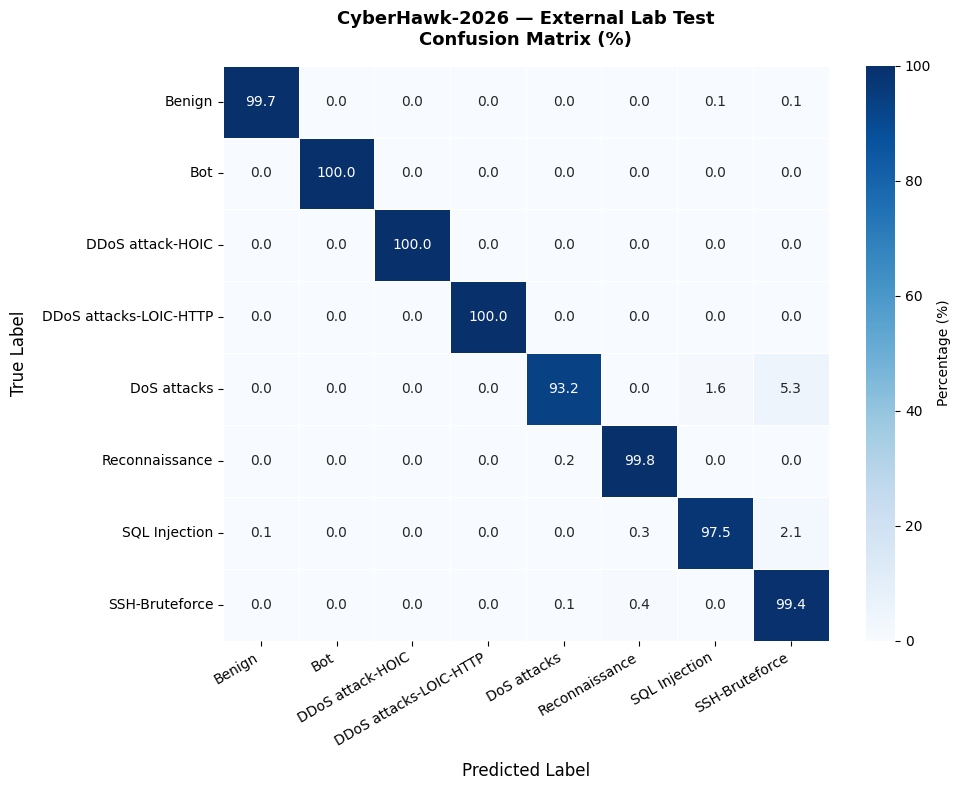

✅ Confusion Matrix Saved


In [35]:
# ╔══════════════════════════════════════════════════════════╗
# ║      CELL 6 — Confusion Matrix                           ║
# ╚══════════════════════════════════════════════════════════╝

cm     = confusion_matrix(y_true, y_pred, labels=present_classes)
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    cm_pct, annot=True, fmt='.1f', cmap='Blues',
    xticklabels=present_names,
    yticklabels=present_names,
    linewidths=0.5, ax=ax,
    cbar_kws={'label': 'Percentage (%)'}
)
ax.set_xlabel('Predicted Label', fontsize=12, labelpad=10)
ax.set_ylabel('True Label', fontsize=12, labelpad=10)
ax.set_title('CyberHawk-2026 — External Lab Test\nConfusion Matrix (%)',
             fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=30, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.savefig(OUT_PATH + 'confusion_matrix_external.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("✅ Confusion Matrix Saved")

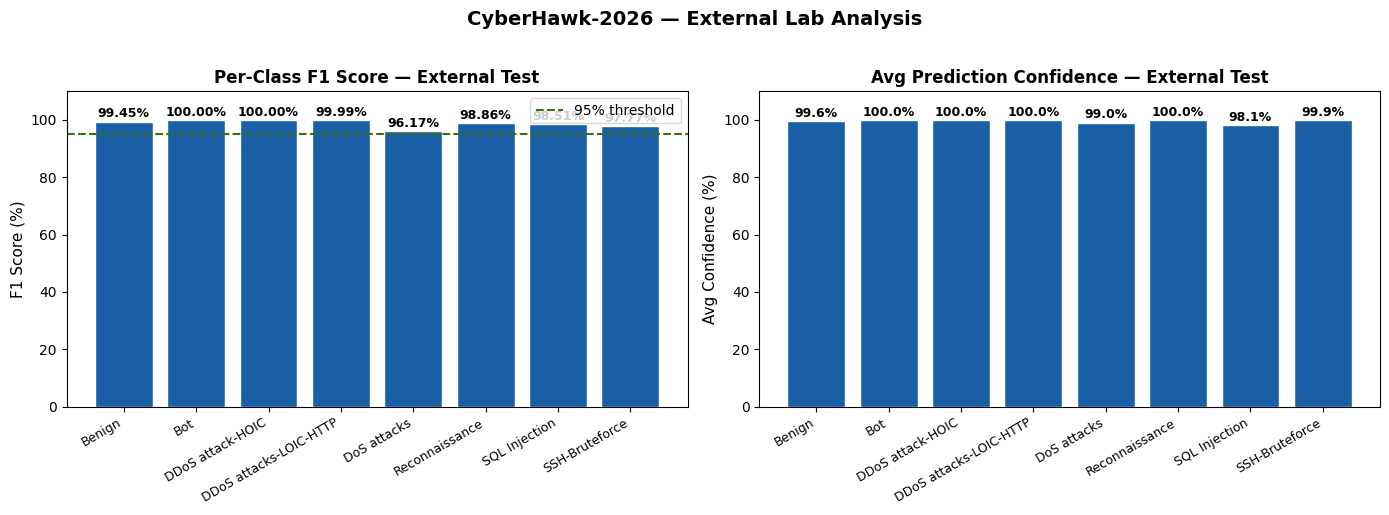

✅ Analysis Plot Saved


In [36]:
# ╔══════════════════════════════════════════════════════════╗
# ║      CELL 7 — Per-Class F1 + Confidence                  ║
# ╚══════════════════════════════════════════════════════════╝

f1_per_class = f1_score(y_true, y_pred, average=None,
                        labels=present_classes)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Per-class F1
colors = ['#185FA5' if f >= 0.95 else '#D85A30' if f < 0.80 else '#BA7517'
          for f in f1_per_class]
bars = axes[0].bar(present_names, f1_per_class * 100,
                   color=colors, edgecolor='white')
for bar, val in zip(bars, f1_per_class):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5,
                 f'{val*100:.2f}%',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[0].set_ylim([0, 110])
axes[0].set_ylabel('F1 Score (%)', fontsize=11)
axes[0].set_title('Per-Class F1 Score — External Test',
                  fontsize=12, fontweight='bold')
axes[0].axhline(y=95, color='#3B6D11', linewidth=1.5,
                linestyle='--', label='95% threshold')
axes[0].legend(fontsize=10)
plt.setp(axes[0].get_xticklabels(), rotation=30, ha='right', fontsize=9)

# Confidence per class
conf_per_class = []
for cls_idx in present_classes:
    mask = y_true == cls_idx
    conf_per_class.append(y_conf[mask].mean() * 100)

axes[1].bar(present_names, conf_per_class,
            color='#185FA5', edgecolor='white')
for i, val in enumerate(conf_per_class):
    axes[1].text(i, val + 0.5, f'{val:.1f}%',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[1].set_ylim([0, 110])
axes[1].set_ylabel('Avg Confidence (%)', fontsize=11)
axes[1].set_title('Avg Prediction Confidence — External Test',
                  fontsize=12, fontweight='bold')
plt.setp(axes[1].get_xticklabels(), rotation=30, ha='right', fontsize=9)

plt.suptitle('CyberHawk-2026 — External Lab Analysis',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT_PATH + 'analysis_external.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("✅ Analysis Plot Saved")